# 00 · Start Here — What ML Is, and the Python You Need

**Who this is for:** someone seeing machine learning for the first time. No prior ML knowledge is assumed. You should know basic Python (variables, loops, functions, lists).

**What you'll learn in this notebook**
1. What "machine learning" actually means, in plain English
2. The three families of ML problems
3. The standard ML workflow (the same 6 steps every project follows)
4. The Python toolkit: **pure Python → NumPy → pandas → matplotlib → scikit-learn**
5. Your first complete ML model in ~10 lines

> **How every notebook in this series works.** Each algorithm is shown **three ways**:
> 1. 🐍 **Pure Python** — only lists and loops. Slow, but every step is visible. This is how you *understand* it.
> 2. 🔢 **NumPy** — the same maths written with arrays. Short, fast, and close to the formula on paper.
> 3. 📦 **Library** (scikit-learn / PyTorch) — what you'd actually use at work. We check it gives the same answer as ours.
>
> Run cells top to bottom with **Shift + Enter**. Change numbers and re-run — breaking things is how you learn.

## 1. What is machine learning?

Traditional programming: **you** write the rules.
```
rules + data  →  answers
"if email contains 'FREE MONEY' then spam"
```
Machine learning: you give **examples with answers**, and the computer **finds the rules**.
```
data + answers  →  rules (a "model")
10,000 emails each labelled spam / not-spam  →  a spam detector
```

A **model** is just a function with adjustable knobs (called **parameters** or **weights**). "Training" or "learning" means **turning the knobs until the function's outputs match the known answers as closely as possible**. Everything else in ML is detail about:
- *what kind of function* (a line? a tree? a neural network?),
- *how we measure "close"* (the **loss function**), and
- *how we turn the knobs* (the **optimiser**, e.g. gradient descent).

Keep those three questions in mind — every algorithm in this series answers them.

## 2. The three families of ML problems

| Family | You have… | Goal | Examples |
|---|---|---|---|
| **Supervised learning** | inputs **X** *and* correct answers **y** | learn X → y | house price from size (**regression**: y is a number); spam or not (**classification**: y is a category) |
| **Unsupervised learning** | inputs **X** only | find structure | group customers into segments (**clustering**); compress 100 features to 2 (**dimensionality reduction**) |
| **Reinforcement learning** | an environment that gives rewards | learn actions that maximise reward | game-playing agents, robot control |

Vocabulary you'll see everywhere:
- **Sample / example / row** — one data point (one house, one email).
- **Feature** — one measured input column (size, number of bedrooms).
- **Label / target** — the answer we want to predict (price).
- **X** has shape `(n_samples, n_features)`; **y** has shape `(n_samples,)`.

## 3. The ML workflow (memorise this — it never changes)

1. **Define the problem.** What are we predicting? How will we know it's good?
2. **Get & explore the data.** Look at it! Plot it. Check for missing values and weird numbers.
3. **Split the data** into a *training set* (to learn from) and a *test set* (kept hidden, to check honestly at the end).
4. **Prepare features.** Scale numbers, encode categories, fill missing values.
5. **Train a model** on the training set — start simple.
6. **Evaluate** on the test set. Iterate on steps 4–5. Never tune on the test set (that's cheating — see notebook 03).

## 4. The Python toolkit

### 4.1 Pure Python vs NumPy — why NumPy exists

ML is mostly arithmetic on long lists of numbers. Let's compute a **dot product** (multiply matching elements, then add up) — the single most common operation in ML.

$$ \mathbf{a} \cdot \mathbf{b} = a_1 b_1 + a_2 b_2 + \dots + a_n b_n $$

In [1]:
# 🐍 Pure Python: a loop, exactly like the formula
def dot_python(a, b):
    total = 0.0
    for ai, bi in zip(a, b):
        total += ai * bi
    return total

print(dot_python([1, 2, 3], [4, 5, 6]))   # 1*4 + 2*5 + 3*6 = 32

32.0


In [2]:
# 🔢 NumPy: the same thing, one call
import numpy as np

a = np.array([1, 2, 3])
b = np.array([4, 5, 6])
print(a @ b)          # '@' means matrix/dot product
print(np.dot(a, b))   # same thing

32
32


Same answer. So why bother? **Speed.** NumPy runs the loop in compiled C code instead of the Python interpreter. Let's time it on a million numbers:

In [3]:
import time, random

n = 1_000_000
a_list = [random.random() for _ in range(n)]
b_list = [random.random() for _ in range(n)]
a_np, b_np = np.array(a_list), np.array(b_list)

t0 = time.perf_counter(); dot_python(a_list, b_list); t_py = time.perf_counter() - t0
t0 = time.perf_counter(); a_np @ b_np;               t_np = time.perf_counter() - t0
print(f"pure Python: {t_py*1000:.1f} ms   NumPy: {t_np*1000:.2f} ms   → NumPy is ~{t_py/t_np:.0f}x faster")

pure Python: 41.8 ms   NumPy: 1.35 ms   → NumPy is ~31x faster


This is called **vectorisation**: replace Python loops with whole-array operations. Here are the NumPy operations you'll use 90% of the time:

In [4]:
X = np.array([[1.0, 2.0],
              [3.0, 4.0],
              [5.0, 6.0]])          # a matrix: 3 rows (samples) × 2 columns (features)

print("shape:", X.shape)           # (3, 2)
print("first row:", X[0])          # [1. 2.]
print("first column:", X[:, 0])    # [1. 3. 5.]   ':' means "all rows"
print("element-wise ×2:\n", X * 2) # every element doubled — no loop needed
print("column means:", X.mean(axis=0))   # axis=0 → collapse rows → one value per column
print("row sums:", X.sum(axis=1))        # axis=1 → collapse columns → one value per row

shape: (3, 2)
first row: [1. 2.]
first column: [1. 3. 5.]
element-wise ×2:
 [[ 2.  4.]
 [ 6.  8.]
 [10. 12.]]
column means: [3. 4.]
row sums: [ 3.  7. 11.]


**Broadcasting** — NumPy automatically stretches a smaller array to match a bigger one. This is how we "standardise" features (subtract each column's mean, divide by its standard deviation) in one line:

In [5]:
X_std = (X - X.mean(axis=0)) / X.std(axis=0)   # (3,2) - (2,)  → the (2,) is reused for every row
print(X_std)
print("new column means ≈ 0:", X_std.mean(axis=0).round(6))
print("new column stds  = 1:", X_std.std(axis=0))

[[-1.22474487 -1.22474487]
 [ 0.          0.        ]
 [ 1.22474487  1.22474487]]
new column means ≈ 0: [0. 0.]
new column stds  = 1: [1. 1.]


**Matrix × vector** is how a linear model makes predictions for *all* samples at once. If `w` holds one weight per feature, `X @ w` gives one prediction per row:

In [6]:
w = np.array([0.5, -1.0])
print(X @ w)    # row 1: 1*0.5 + 2*(-1) = -1.5, etc.

# The pure-Python equivalent, to see what @ does:
print([sum(xij * wj for xij, wj in zip(row, w)) for row in X.tolist()])

[-1.5 -2.5 -3.5]
[np.float64(-1.5), np.float64(-2.5), np.float64(-3.5)]


### 4.2 pandas — tables with labels

NumPy arrays are just numbers. **pandas** `DataFrame`s add column names and handy tools for messy real data. Use pandas to *load and clean*, NumPy/scikit-learn to *model*.

In [7]:
import pandas as pd

df = pd.DataFrame({
    "size_m2":  [50, 80, 120, 65, None, 95],
    "bedrooms": [1, 2, 3, 2, 2, 3],
    "city":     ["A", "B", "A", "B", "A", "B"],
    "price_k":  [150, 240, 370, 200, 210, 300],
})
df

,size_m2,bedrooms,city,price_k
0,50.0,1,A,150
1,80.0,2,B,240
2,120.0,3,A,370
3,65.0,2,B,200
4,NaN,2,A,210
5,95.0,3,B,300


In [8]:
print(df.describe())                 # quick statistics for numeric columns
print("\nmissing per column:\n", df.isna().sum())

          size_m2  bedrooms     price_k
count    5.000000  6.000000    6.000000
mean    82.000000  2.166667  245.000000
std     27.064737  0.752773   78.676553
min     50.000000  1.000000  150.000000
25%     65.000000  2.000000  202.500000
50%     80.000000  2.000000  225.000000
75%     95.000000  2.750000  285.000000
max    120.000000  3.000000  370.000000

missing per column:
 size_m2     1
bedrooms    0
city        0
price_k     0
dtype: int64


In [9]:
# Typical cleaning steps
df["size_m2"] = df["size_m2"].fillna(df["size_m2"].median())   # fill the missing value
df = pd.get_dummies(df, columns=["city"], dtype=int)              # turn text category into 0/1 columns ("one-hot")
X = df.drop(columns="price_k").to_numpy()                        # features as a NumPy array
y = df["price_k"].to_numpy()                                     # target
df

,size_m2,bedrooms,price_k,city_A,city_B
0,50.0,1,150,1,0
1,80.0,2,240,0,1
2,120.0,3,370,1,0
3,65.0,2,200,0,1
4,80.0,2,210,1,0
5,95.0,3,300,0,1


### 4.3 matplotlib — always look at your data

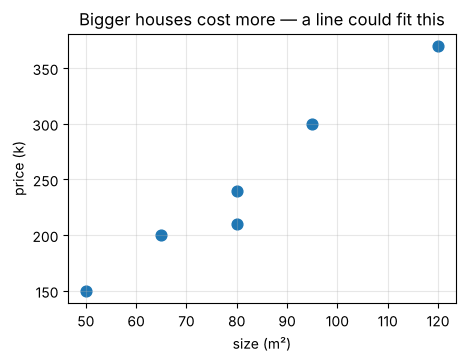

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5, 3.5))
plt.scatter(df["size_m2"], df["price_k"], s=60)
plt.xlabel("size (m²)"); plt.ylabel("price (k)"); plt.title("Bigger houses cost more — a line could fit this")
plt.grid(alpha=0.3); plt.show()

## 5. Your first ML model, end to end

We'll use the famous **Iris** dataset (bundled with scikit-learn): 150 flowers, 4 measurements each, 3 species. Task: **predict the species from the measurements** — a classification problem.

Every scikit-learn model has the same interface:
```python
model = SomeModel(settings)
model.fit(X_train, y_train)     # learn
model.predict(X_new)            # use
```

In [11]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

X, y = load_iris(return_X_y=True)
print("X shape:", X.shape, " y shape:", y.shape, " classes:", np.unique(y))

# Step 3: split — 75% to learn from, 25% hidden for an honest check
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)

# Step 5: train
model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train, y_train)

# Step 6: evaluate on data the model has never seen
pred = model.predict(X_test)
print("test accuracy:", accuracy_score(y_test, pred))

X shape: (150, 4)  y shape: (150,)  classes: [0 1 2]
test accuracy: 1.0


That's a real ML model, ~97% accurate on flowers it never saw. The remaining notebooks open the box and show **how** models like this work inside.

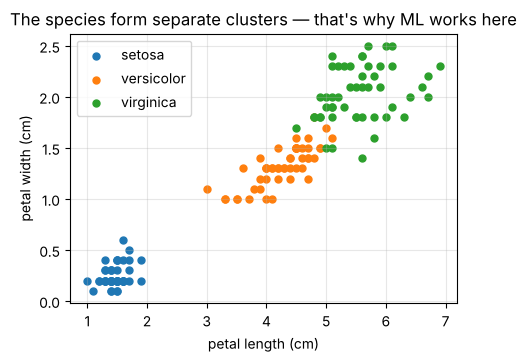

In [12]:
# Look at the data the model learned from (2 of the 4 features)
plt.figure(figsize=(5, 3.5))
for c, name in enumerate(load_iris().target_names):
    plt.scatter(X[y == c, 2], X[y == c, 3], label=name, s=25)
plt.xlabel("petal length (cm)"); plt.ylabel("petal width (cm)"); plt.legend(); plt.grid(alpha=0.3)
plt.title("The species form separate clusters — that's why ML works here"); plt.show()

## 6. Key takeaways
- A **model** is a function with knobs; **training** = adjusting knobs to fit known answers.
- Supervised (X + y), unsupervised (X only), reinforcement (rewards).
- Always **split** before training; judge the model only on the held-out test set.
- Write loops to *understand*, write NumPy to *be fast*, use libraries to *ship*.

## 7. Exercises
1. Change `n_neighbors` to 1 and to 50. What happens to test accuracy? (Notebook 04 explains why.)
2. Write `matvec_python(X, w)` using only loops and check it matches `X @ w`.
3. Load `sklearn.datasets.load_wine` and repeat Section 5. What accuracy do you get? Try standardising X first.

In [13]:
# Exercise 2 — solution (try it yourself first!)
def matvec_python(X, w):
    return [sum(x * wj for x, wj in zip(row, w)) for row in X]

Xs = [[1.0, 2.0], [3.0, 4.0]]; ws = [0.5, -1.0]
print(matvec_python(Xs, ws), np.array(Xs) @ np.array(ws))

[-1.5, -2.5] [-1.5 -2.5]


**Next:** [01 · Linear Regression](01_linear_regression.ipynb) — the simplest model, and the foundation for almost everything else.

*Going deeper / interview prep:* `ML_Interview_Notes.md` Part 0 (cheat sheet) and `Linear_Algebra_Notes.md` Parts 1–2.